<a href="https://colab.research.google.com/github/anel-ra/ml-model-creation/blob/main/notebook/product_category_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predikcija kategorije proizvoda na osnovu naslova
Autor: **Anel Rakaj**

## 1. Loading and Inspecting the Dataset

In this section, we will import the necessary libraries, load our dataset into a Pandas DataFrame, and perform an initial inspection to understand its structure, dimensions, and data types.

In [14]:
import pandas as pd

# load dataset from GitHub
url = "https://raw.githubusercontent.com/anel-ra/ml-model-creation/main/data/products.csv"
df = pd.read_csv(url)

# Print shape (number of rows and columns)
print("Dataset shape (rows, columns):", df.shape)

# Show first 5 rows
print("\nFirst 5 rows:")
display(df.head())

# Show column data types and non-null counts
print("\nDataset info:")
df.info()

Dataset shape (rows, columns): (35311, 8)

First 5 rows:


,product ID,Product Title,Merchant ID,Category Label,_Product Code,Number_of_Views,Merchant Rating,Listing Date
0,1,apple iphone 8 plus 64gb silver,1,Mobile Phones,QA-2276-XC,860.0,2.5,5/10/2024
1,2,apple iphone 8 plus 64 gb spacegrau,2,Mobile Phones,KA-2501-QO,3772.0,4.8,12/31/2024
2,3,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,3,Mobile Phones,FP-8086-IE,3092.0,3.9,11/10/2024
3,4,apple iphone 8 plus 64gb space grey,4,Mobile Phones,YI-0086-US,466.0,3.4,5/2/2022
4,5,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,5,Mobile Phones,NZ-3586-WP,4426.0,1.6,4/12/2023



Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35311 entries, 0 to 35310
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   product ID       35311 non-null  int64  
 1   Product Title    35139 non-null  object 
 2   Merchant ID      35311 non-null  int64  
 3    Category Label  35267 non-null  object 
 4   _Product Code    35216 non-null  object 
 5   Number_of_Views  35297 non-null  float64
 6   Merchant Rating  35141 non-null  float64
 7    Listing Date    35252 non-null  object 
dtypes: float64(2), int64(2), object(4)
memory usage: 2.2+ MB


2. Basic Dataset Overview
Before training any model, missing values and category distribution.

In [15]:
# Count missing values per column
print("Missing values per column:")
print(df.isna().sum())

print("Trenutne kolone u df:", df.columns.tolist())
# Count occurrences of each Category Label
Category_Label_counts = df[' Category Label'].value_counts()

# Print counts
print("Category Label distribution (counts):")
print(Category_Label_counts)



Missing values per column:
product ID           0
Product Title      172
Merchant ID          0
 Category Label     44
_Product Code       95
Number_of_Views     14
Merchant Rating    170
 Listing Date       59
dtype: int64
Trenutne kolone u df: ['product ID', 'Product Title', 'Merchant ID', ' Category Label', '_Product Code', 'Number_of_Views', 'Merchant Rating', ' Listing Date  ']
Category Label distribution (counts):
 Category Label
Fridge Freezers     5495
Washing Machines    4036
Mobile Phones       4020
CPUs                3771
TVs                 3564
Fridges             3457
Dishwashers         3418
Digital Cameras     2696
Microwaves          2338
Freezers            2210
fridge               123
CPU                   84
Mobile Phone          55
Name: count, dtype: int64


# 5. Data Preparation and Cleaning

In this step, we handle missing values, standardize text and numeric features, and prepare the dataset for feature engineering and modeling.

---

## 5.1 Handling Missing Values
We check for missing values across all columns, especially focusing on critical fields like `Product Title`, `Category Label`, and numerical values (`Number of Views`, `Merchant Rating`).

In [16]:
# Drop all rows with missing values
df = df.dropna()

# Display new shape of the dataset
print("New dataset shape:", df.shape)

# Count missing values per column
print("Missing values per column:")
print(df.isna().sum())

df.columns = df.columns.str.strip()

# Standardize Category Label column to lowercase
df['Category Label'] = df['Category Label'].str.strip().str.lower()

# Standardize Category Label column
mapping = {
    "cpu": "cpus",
    "fridge": "fridges",
    "mobile phone": "mobile phones"
}
df['Category Label'] = df['Category Label'].replace(mapping).astype("category")

print(df['Category Label'].unique())
print(df['Category Label'].value_counts())




New dataset shape: (34760, 8)
Missing values per column:
product ID         0
Product Title      0
Merchant ID        0
 Category Label    0
_Product Code      0
Number_of_Views    0
Merchant Rating    0
 Listing Date      0
dtype: int64
['mobile phones', 'tvs', 'cpus', 'digital cameras', 'microwaves', 'dishwashers', 'washing machines', 'freezers', 'fridge freezers', 'fridges']
Categories (10, object): ['cpus', 'digital cameras', 'dishwashers', 'freezers', ...,
                          'microwaves', 'mobile phones', 'tvs', 'washing machines']
Category Label
fridge freezers     5424
mobile phones       4023
washing machines    3971
cpus                3792
fridges             3524
tvs                 3502
dishwashers         3374
digital cameras     2661
microwaves          2307
freezers            2182
Name: count, dtype: int64


# 6. Feature Engineering ⚙️

We will create new features from the existing columns to help our Machine Learning models capture patterns effectively.

In [17]:
# Drop columns that are not useful for modeling
df = df.drop(columns=['product ID', 'Merchant ID', '_Product Code', 'Number_of_Views', 'Merchant Rating', 'Listing Date'])

# Preview remaining columns
print("Remaining columns:")
print(df.columns.tolist())

Remaining columns:
['Product Title', 'Category Label']


## 6.1 Text-Based Features
Extracting components from `Product Title`:
* **Title Length**:
Longer titles might indicate specific electronic models

Title length summary:
count    34760.000000
mean        52.972066
std         22.417916
min          5.000000
25%         39.000000
50%         52.000000
75%         65.000000
max        200.000000
Name: Title Length, dtype: float64
Title length statistics by CL:
                   count       mean        std   min   25%   50%   75%    max
Category Label                                                               
cpus              3792.0  67.016350  20.259078  11.0  55.0  65.0  76.0  190.0
digital cameras   2661.0  50.118001  24.512564   6.0  34.0  44.0  61.0  180.0
dishwashers       3374.0  50.184351  17.939197  10.0  39.0  51.0  61.0  192.0
freezers          2182.0  48.705775  18.132038  10.0  37.0  47.0  60.0  168.0
fridge freezers   5424.0  55.266777  20.467733   9.0  42.0  54.0  68.0  170.0
fridges           3524.0  48.495743  18.344180   8.0  36.0  46.0  62.0  173.0
microwaves        2307.0  51.788903  18.850512  11.0  39.0  52.0  65.0  164.0
mobile phones     4023.0  46.15510

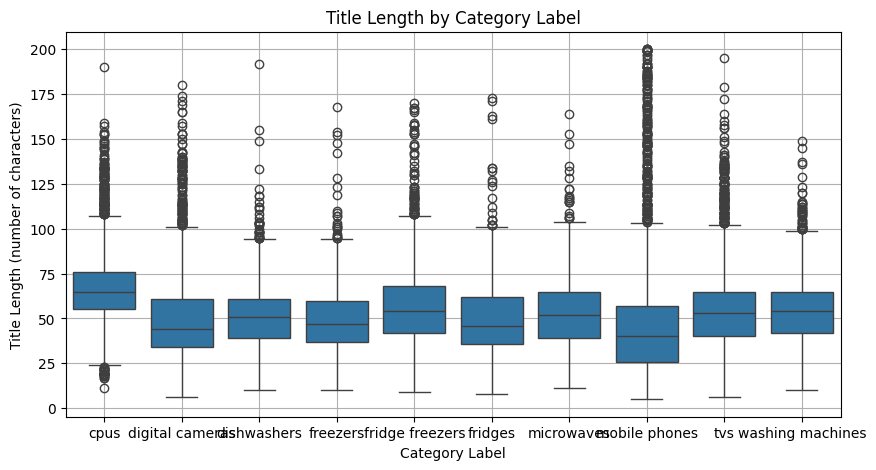

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create new column with length
df['Title Length'] = df['Product Title'].astype(str).str.len()

# Show basic stats
print("Title length summary:")
print(df['Title Length'].describe())

# Group by category label and describe title length
print("Title length statistics by CL:")
print(df.groupby('Category Label', observed=False)['Title Length'].describe())

# Visualize distribution of review length by sentiment
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='Category Label', y='Title Length')
plt.title("Title Length by Category Label")
plt.xlabel("Category Label")
plt.ylabel("Title Length (number of characters)")
plt.grid(True)
plt.show()

# 7. Model Evaluation and Comparison 🤖

We will split the data into training and testing sets, vectorize the text data using **TF-IDF**, and compare multiple Machine Learning algorithms to find the best balance between precision, robustness, and interpretability.

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report


# Features and label
X = df[["Product Title", "Title Length"]]
y = df["Category Label"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(

X, y, test_size=0.2, random_state=42, stratify=y
)


# Preprocessor: TF-IDF for text, MinMaxScaler for numeric feature
preprocessor = ColumnTransformer(
    transformers=[
("title", TfidfVectorizer(), "Product Title"),
("length", MinMaxScaler(), ["Title Length"])
    ]
)

# List of classifiers
models = {
  "Logistic Regression": LogisticRegression(max_iter=1000),
  "Naive Bayes": MultinomialNB(),
  "Decision Tree": DecisionTreeClassifier(),
  "Random Forest": RandomForestClassifier(),
  "Support Vector Machine": LinearSVC()
  }
# Train and evaluate
for name, model in models.items():
    print(f"\n=== {name} ===")
    pipeline = Pipeline ([
          ("preprocessor", preprocessor),
          ("classifier", model),
    ])
    pipeline.fit(X_train,y_train)
    y_pred = pipeline.predict(X_test)

    print(classification_report(y_test, y_pred))


=== Logistic Regression ===
                  precision    recall  f1-score   support

            cpus       1.00      0.99      1.00       758
 digital cameras       1.00      0.99      0.99       532
     dishwashers       0.90      0.97      0.93       675
        freezers       0.99      0.91      0.94       436
 fridge freezers       0.96      0.93      0.94      1085
         fridges       0.91      0.91      0.91       705
      microwaves       1.00      0.95      0.97       461
   mobile phones       0.96      0.99      0.98       805
             tvs       0.97      0.98      0.97       701
washing machines       0.94      0.95      0.95       794

        accuracy                           0.96      6952
       macro avg       0.96      0.96      0.96      6952
    weighted avg       0.96      0.96      0.96      6952


=== Naive Bayes ===
                  precision    recall  f1-score   support

            cpus       1.00      1.00      1.00       758
 digital cameras  